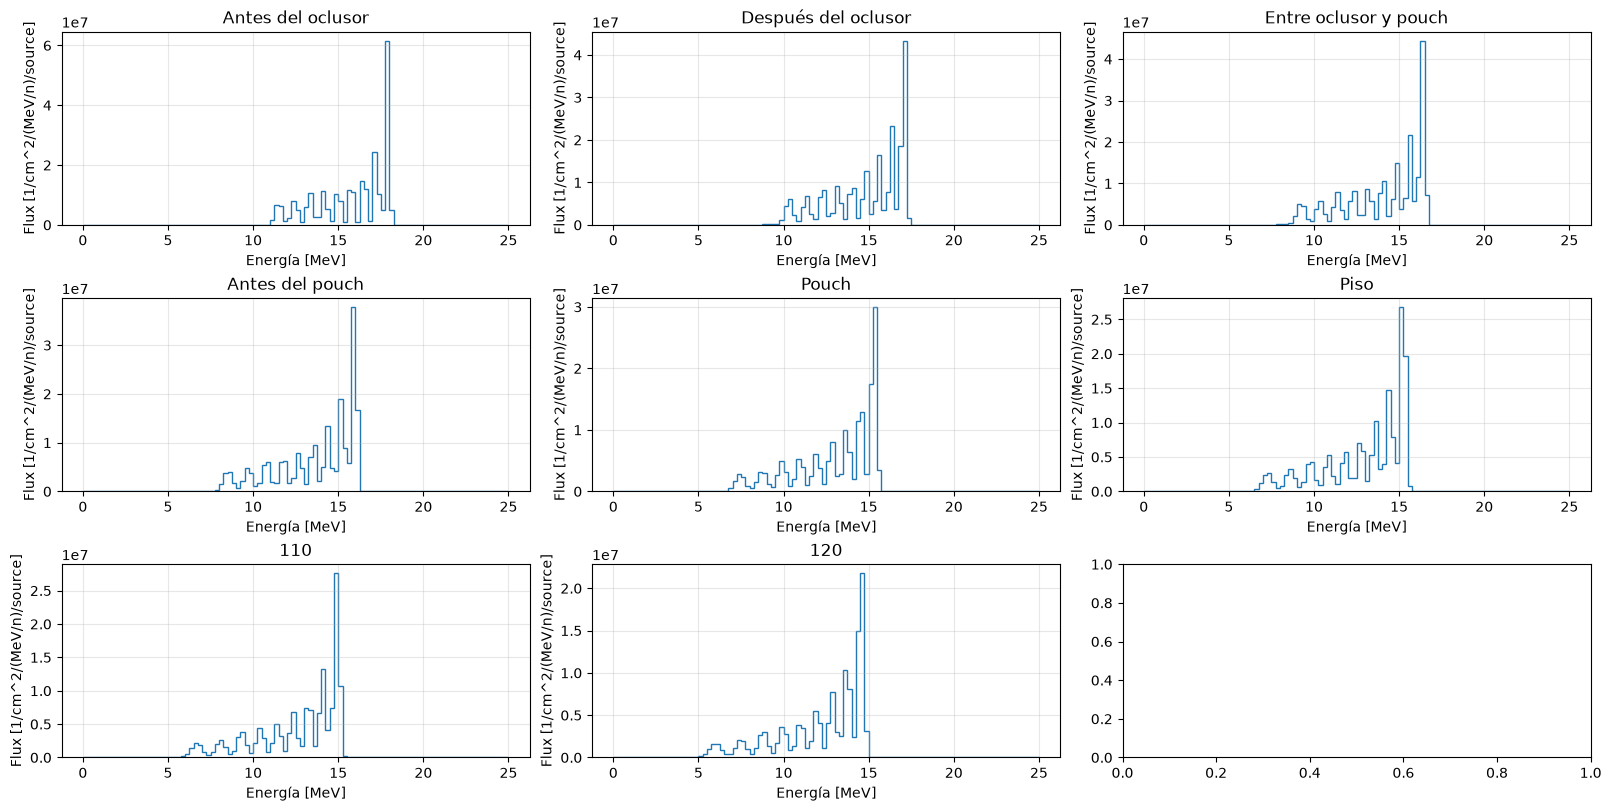

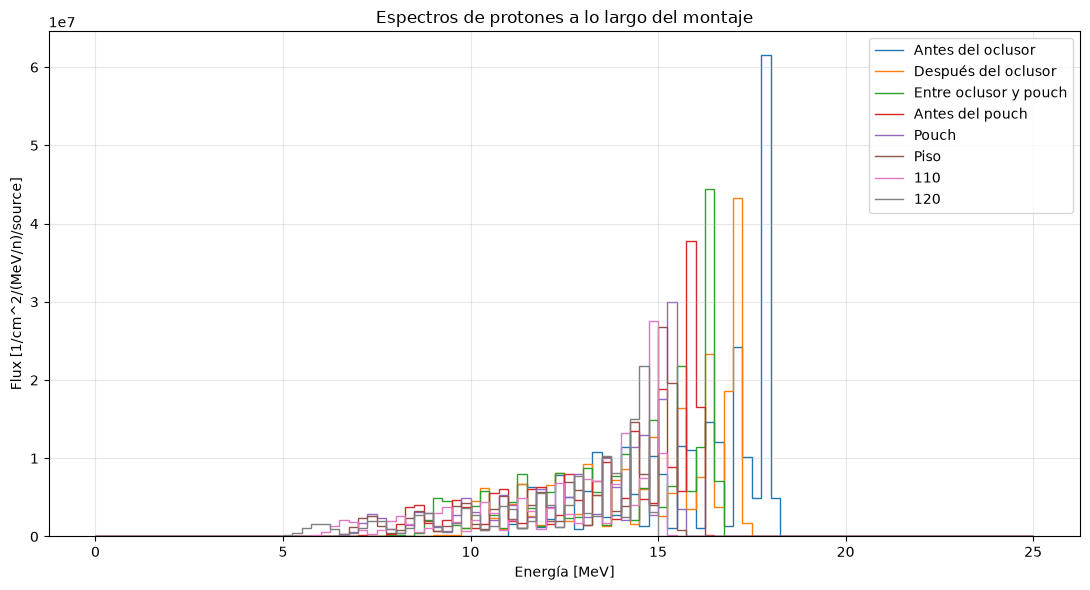

             Posición  Fluencia integrada [1/cm²/source]  Energía media [MeV]  Energía máxima [MeV]  Relativa al primer plano [%]
    Antes del oclusor                       6.219004e+07            15.785407                 18.25                    100.000000
  Después del oclusor                       5.721544e+07            14.847556                 17.75                     92.000965
Entre oclusor y pouch                       5.568258e+07            14.080897                 17.00                     89.536170
      Antes del pouch                       5.160621e+07            13.643466                 16.75                     82.981468
                Pouch                       4.292158e+07            13.016228                 16.00                     69.016813
                 Piso                       4.169365e+07            12.928089                 16.00                     67.042329
                  110                       3.713373e+07            12.597550             

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

carpeta = Path('..') / 'out/'

archivos = {
    'Antes del oclusor': 'espectro_antes_oclusor.out',
    'Después del oclusor': 'espectro_despues_oclusor.out',
    'Entre oclusor y pouch': 'espectro_entre_oc_y_pouch.out',
    'Antes del pouch': 'espectro_antes_pouch.out',
    'Pouch': 'espectro_pouch.out',
    'Piso': 'espectro_piso.out',
    '110' : 'espectro_110.out',
    '120' : 'espectro_120.out'
}


def leer_espectro(ruta):
    if not ruta.is_file():
        raise FileNotFoundError(f'No encuentro {ruta.resolve()}')

    lineas = ruta.read_text(encoding='utf-8', errors='replace').splitlines()
    bloques = []
    ylabel = ''

    for i, linea in enumerate(lineas):
        s = linea.strip()
        if re.match(r'^y\s*:', s, flags=re.I):
            ylabel = s.split(':', 1)[1].strip()

        if not s.startswith('#'):
            continue

        encabezado = s.lstrip('#').split()
        nombres = [c.lower() for c in encabezado]
        if len(nombres) < 4 or nombres[:2] != ['e-lower', 'e-upper']:
            continue

        columnas_particulas = [k for k in range(2, len(nombres) - 1, 2)]
        columna = next((k for k in columnas_particulas if nombres[k].strip('(),') in ('proton', 'p')), None)
        if columna is None:
            if len(columnas_particulas) == 1:
                columna = columnas_particulas[0]
                print(f'Aviso: {ruta.name}: solo encontré la partícula {encabezado[columna]}.')
            else:
                raise ValueError(f'{ruta.name}: no encontré la columna proton en {encabezado}')

        datos = []
        for siguiente in lineas[i + 1:]:
            tokens = siguiente.strip().split()
            if not tokens:
                if datos:
                    break
                continue
            if tokens[0].startswith('#'):
                if datos:
                    break
                continue
            try:
                valores = [float(v.replace('D', 'E').replace('d', 'e')) for v in tokens]
            except ValueError:
                if datos:
                    break
                continue
            if len(valores) < columna + 2:
                if datos:
                    break
                continue
            datos.append((valores[0], valores[1], valores[columna], valores[columna + 1]))

        if datos:
            bloques.append((np.asarray(datos, dtype=float), ylabel, encabezado[columna]))

    if not bloques:
        candidatos = [(n, l.strip()) for n, l in enumerate(lineas, 1)
                      if re.search(r'e[-_ ]?lower|e[-_ ]?upper|axis\s*=', l, flags=re.I)]
        detalle = '\n'.join(f'  Línea {n}: {s[:140]}' for n, s in candidatos[:15])
        if not detalle:
            detalle = '\n'.join(f'  {n}: {l[:140]}' for n, l in enumerate(lineas[:25], 1))
        raise ValueError(
            f'{ruta.name}: no pude reconocer una tabla de espectro de energía.\n'
            f'Cabeceras o indicios detectados:\n{detalle}\n'
            'Revisá que el tally sea un espectro 1D (por ejemplo, axis = eng).'
        )

    if len(bloques) > 1:
        print(f'Aviso: {ruta.name}: encontré {len(bloques)} páginas y estoy usando la primera.')

    matriz, ylabel, particula = bloques[0]
    emin, emax, phi, err_rel = matriz.T
    if not np.all(np.isfinite(matriz)):
        raise ValueError(f'{ruta.name}: aparecen valores no finitos en la tabla')
    if not np.all(emax > emin):
        raise ValueError(f'{ruta.name}: los intervalos de energía no son válidos')
    if not np.all(np.diff(emin) >= 0):
        raise ValueError(f'{ruta.name}: la energía no está ordenada')

    ancho = emax - emin
    diferencial = bool(re.search(r'/(?:\s*MeV|\s*\(MeV)', ylabel, flags=re.I))
    peso = phi * ancho if diferencial else phi
    total = np.sum(peso)
    energia_media = np.sum(((emin + emax) / 2) * peso) / total if total > 0 else np.nan
    if not ylabel:
        print(f'Aviso: {ruta.name}: no encontré etiqueta del eje Y; verificá si la salida está dividida por MeV.')
    return {
        'E': (emin + emax) / 2,
        'emin': emin,
        'emax': emax,
        'fluencia': phi,
        'error': np.abs(phi * err_rel),
        'total': total,
        'energia_media': energia_media,
        'ylabel': ylabel or 'Fluencia (verificar unidades)',
        'diferencial': diferencial,
        'particula': particula,
    }


espectros = {nombre: leer_espectro(carpeta / archivo) for nombre, archivo in archivos.items()}

fig, axes = plt.subplots(3, 3, figsize=(16, 8), constrained_layout=True)
for ax, (nombre, datos) in zip(axes.flat, espectros.items()):
    ax.stairs(datos['fluencia'], np.r_[datos['emin'], datos['emax'][-1]])
    ax.set(title=nombre, xlabel='Energía [MeV]', ylabel=datos['ylabel'])
    ax.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(11, 6))
for nombre, datos in espectros.items():
    plt.stairs(datos['fluencia'], np.r_[datos['emin'], datos['emax'][-1]], label=nombre)
plt.xlabel('Energía [MeV]')
plt.ylabel(next(iter(espectros.values()))['ylabel'])
plt.title('Espectros de protones a lo largo del montaje')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

modos = {d['diferencial'] for d in espectros.values()}
if len(modos) > 1:
    raise ValueError('Algunos tallies dan fluencia por MeV y otros por intervalo; revisá las unidades antes de comparar.')

primera_fluencia = next(iter(espectros.values()))['total']
resumen = pd.DataFrame([
    {
        'Posición': nombre,
        'Fluencia integrada [1/cm²/source]': d['total'],
        'Energía media [MeV]': d['energia_media'],
        'Energía máxima [MeV]': np.max(d['emax'][d['fluencia'] > 0]) if np.any(d['fluencia'] > 0) else np.nan,
        'Relativa al primer plano [%]': 100 * d['total'] / primera_fluencia if primera_fluencia > 0 else np.nan,
    }
    for nombre, d in espectros.items()
])
print(resumen.to_string(index=False))


In [2]:


print("Directorio de trabajo:", Path.cwd())
print("Carpeta de datos:", carpeta.resolve())

for nombre, archivo in archivos.items():
    ruta = (carpeta / archivo).resolve()
    print(f"\n{nombre}: {ruta}")
    print("Existe:", ruta.is_file())

Directorio de trabajo: c:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\analisis
Carpeta de datos: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out

Antes del oclusor: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out\espectro_antes_oclusor.out
Existe: True

Después del oclusor: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out\espectro_despues_oclusor.out
Existe: True

Entre oclusor y pouch: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out\espectro_entre_oc_y_pouch.out
Existe: True

Antes del pouch: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz_oclusor_chico\out\espectro_antes_pouch.out
Existe: True

Pouch: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 

In [ ]:

resultados_maximos = [] 

for nombre, datos in espectros.items():
    indice = np.argmax(datos['fluencia'])

    fluencia_maxima = datos['fluencia'][indice]
    energia_pico = datos['E'][indice]

    resultados_maximos.append({
        'Posición': nombre,
        'Fluencia máxima': f"{fluencia_maxima:.3e}",
        'Energía del máximo [MeV]': energia_pico,
        'Intervalo energético [MeV]': (
            f"{datos['emin'][indice]:.3f} - {datos['emax'][indice]:.3f}"
        )
    })

tabla_maximos = pd.DataFrame(resultados_maximos)

display(tabla_maximos)


,Posición,Fluencia máxima,Energía del máximo [MeV],Intervalo energético [MeV]
0,Antes del oclusor,6.150e+07,17.875,17.750 - 18.000
1,Después del oclusor,4.332e+07,17.125,17.000 - 17.250
2,Entre oclusor y pouch,4.440e+07,16.375,16.250 - 16.500
3,Antes del pouch,3.776e+07,15.875,15.750 - 16.000
4,Pouch,2.994e+07,15.375,15.250 - 15.500
5,Piso,2.675e+07,15.125,15.000 - 15.250
6,110,2.758e+07,14.875,14.750 - 15.000
7,120,2.176e+07,14.625,14.500 - 14.750


Posición,z [cm],Energía del máximo [MeV]
Antes del oclusor,33.94,17.875
Después del oclusor,45.00,17.125
Entre oclusor y pouch,66.80,16.375
Antes del pouch,80.00,15.875
Pouch,98.48,15.375
Piso,100.96,15.125


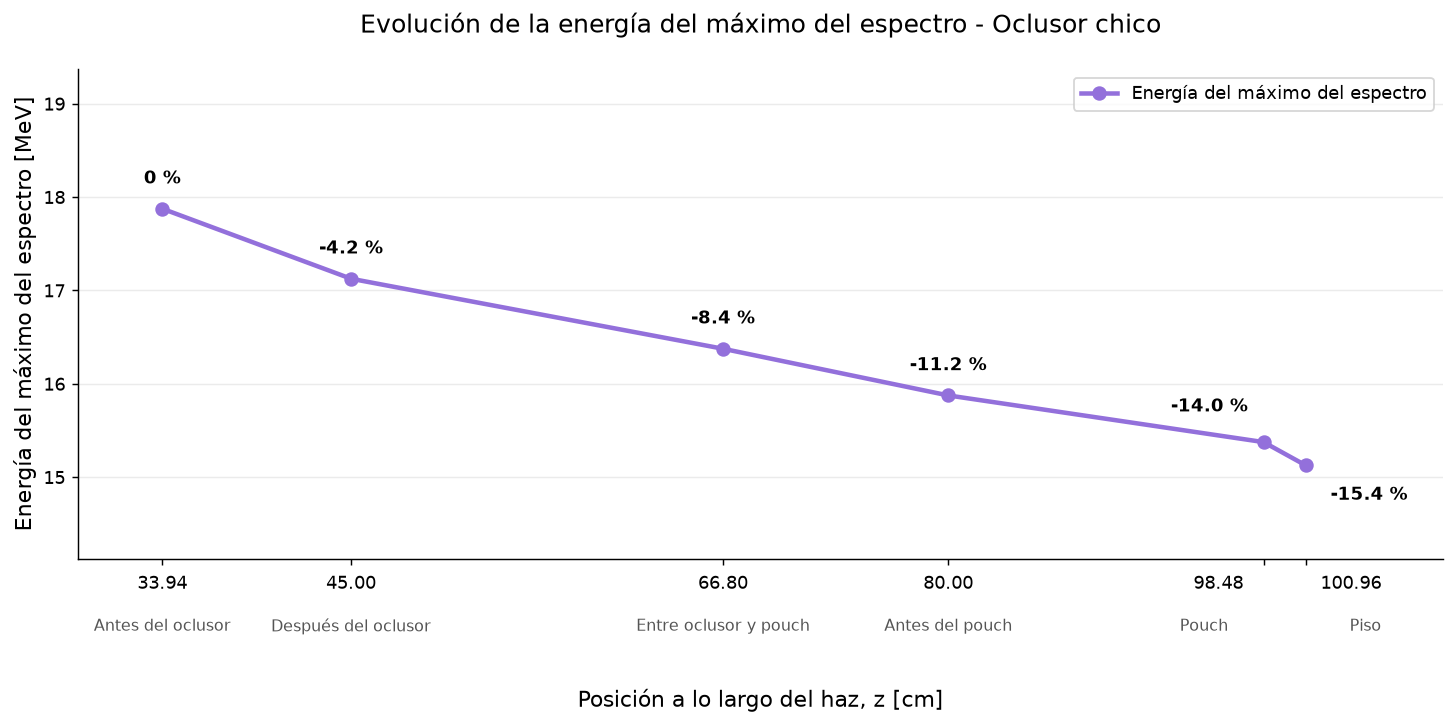

In [4]:
carpeta = Path("..") / "out"

archivos = [
    (33.94, "Antes del oclusor", "espectro_antes_oclusor.out"),
    (45.00, "Después del oclusor", "espectro_despues_oclusor.out"),
    (66.80, "Entre oclusor y pouch", "espectro_entre_oc_y_pouch.out"),
    (80.00, "Antes del pouch", "espectro_antes_pouch.out"),
    (98.48, "Pouch", "espectro_pouch.out"),
    (100.96, "Piso", "espectro_piso.out")
]

def leer_maximo_espectro(ruta):
    filas = []
    leyendo = False

    with open(ruta, encoding="utf-8", errors="replace") as f:
        for linea in f:
            if linea.strip().startswith("#  e-lower"):
                leyendo = True
                continue

            if not leyendo:
                continue

            partes = linea.split()

            if len(partes) != 4:
                if filas:
                    break
                continue

            try:
                emin, emax, fluencia, error = [
                    float(v.replace("D", "E").replace("d", "e"))
                    for v in partes
                ]
            except ValueError:
                if filas:
                    break
                continue

            filas.append((emin, emax, fluencia, error))

    if not filas:
        raise ValueError(f"No se encontraron datos en {ruta}")

    datos = np.array(filas)
    i = np.argmax(datos[:, 2])

    emin, emax, fluencia, error = datos[i]

    return (emin + emax) / 2, fluencia, emin, emax

resultados_energia = []

for z, posicion, nombre in archivos:
    energia, fluencia, emin, emax = leer_maximo_espectro(carpeta / nombre)

    resultados_energia.append({
        "z": z,
        "posicion": posicion,
        "energia": energia,
        "fluencia": fluencia,
        "emin": emin,
        "emax": emax
    })

tabla = pd.DataFrame(resultados_energia)

display(
    tabla[["posicion", "z", "energia"]]
    .rename(columns={
        "posicion": "Posición",
        "z": "z [cm]",
        "energia": "Energía del máximo [MeV]"
    })
    .style
    .hide(axis="index")
    .format({
        "z [cm]": "{:.2f}",
        "Energía del máximo [MeV]": "{:.3f}"
    })
)

z = tabla["z"].to_numpy()
energia_max = tabla["energia"].to_numpy()

variacion = (energia_max / energia_max[0] - 1) * 100

fig, ax = plt.subplots(figsize=(12.5, 6.5), dpi=130)

color = "mediumpurple"

ax.plot(
    z,
    energia_max,
    "o-",
    color=color,
    linewidth=2.5,
    markersize=7,
    label="Energía del máximo del espectro",
    zorder=3
)

desplazamientos = [
    (0, 14),
    (0, 14),
    (0, 14),
    (0, 14),
    (-30, 17),
    (35, -19)
]

for i, (zi, ei, porcentaje) in enumerate(
    zip(z, energia_max, variacion)
):
    texto = "0 %" if i == 0 else f"{porcentaje:+.1f} %"
    dx, dy = desplazamientos[i]

    ax.annotate(
        texto,
        (zi, ei),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xticks(z)
ax.set_xticklabels([])

desplazamientos_z = [0, 0, 0, 0, -25, 25]
desplazamientos_nombre = [0, 0, 0, 0, -33, 33]

for zi, posicion, dx_z, dx_nombre in zip(
    z, tabla["posicion"], desplazamientos_z, desplazamientos_nombre
):
    ax.annotate(
        f"{zi:.2f}",
        xy=(zi, 0),
        xycoords=ax.get_xaxis_transform(),
        xytext=(dx_z, -9),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=10
    )

    ax.annotate(
        posicion,
        xy=(zi, 0),
        xycoords=ax.get_xaxis_transform(),
        xytext=(dx_nombre, -33),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=9,
        color="#555555"
    )

ax.set_xlim(29, 109)
ax.set_ylim(
    min(energia_max) - 1.0,
    max(energia_max) + 1.5
)

ax.set_xlabel(
    "Posición a lo largo del haz, z [cm]",
    fontsize=12,
    labelpad=65
)

ax.set_ylabel(
    "Energía del máximo del espectro [MeV]",
    fontsize=12
)

ax.set_title(
    "Evolución de la energía del máximo del espectro - Oclusor chico",
    fontsize=14,
    pad=20
)

ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.25)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.subplots_adjust(
    left=0.11,
    right=0.95,
    top=0.88,
    bottom=0.30
)

plt.show()
